# Sentiment Analysis & Exploratory Data Analysis (EDA) on Daraz Reviews
### An End-to-End Applied Data Science Study on Roman Urdu & English Code-Mixed E-Commerce Feedback

---
### Notebook Overview & Table of Contents:
1. **Project Introduction and Objective**
2. **Environment Setup & Library Imports**
3. **Data Loading and Initial Inspection**
4. **Data Cleaning and Preprocessing Pipeline**
5. **Exploratory Data Analysis (EDA)**
6. **Supervised Sentiment Classification (TF-IDF + Logistic Regression)**
7. **Comprehensive Data Visualizations & Interpretations**
   - 1. Sentiment Distribution (Counts & Percentages)
   - 2. Sentiment Proportions (Pie Chart)
   - 3. Rating Distribution (1–5 Stars)
   - 4. Rating vs. Sentiment (Normalized Stacked Bar Chart)
   - 5. Review Length Analysis (Histogram & KDE)
   - 6. Sentiment vs. Review Length (Box Plot)
   - 7. Word Clouds (Positive, Negative, Neutral)
   - 8. Most Frequent Words (Top 12 per Sentiment)
   - 9. Confusion Matrix Heatmap
   - 10. Model Evaluation Metrics Comparison
   - 11. Aspect & Feature Frequency vs. Sentiment
8. **Business Insights and Strategic Marketplace Recommendations**
9. **Conclusion & Technical Roadmap**


---
## 1. Project Introduction and Objective

Daraz is the leading e-commerce platform in South Asia (Pakistan, Bangladesh, Sri Lanka, Nepal). User feedback on Daraz is culturally rich and linguistically diverse, heavily featuring **Roman Urdu** (Urdu phonetically transliterated into the Latin script) intertwined with English product terminology.

### Key Objectives:
1. Load, inspect, and rigorously audit the `Daraz Labelled Review Dataset with Sentiments and Features.xlsx` dataset.
2. Clean and preprocess code-mixed Roman Urdu text while strictly preserving negations (`nahi`, `nai`), sentiment modifiers, and product entities.
3. Validate ground truth sentiment labels (`Positive`, `Negative`, `Neutral`) and train a supervised TF-IDF + Logistic Regression classifier.
4. Investigate the alignment and discrepancies between numerical star ratings (1–5) and expressed text sentiments.
5. Create 11 publication-grade visualizations with Matplotlib, Seaborn, and WordCloud.
6. Derive quantifiable business insights and operational recommendations for marketplace management.


In [36]:
# Step 1: Install required packages if running in Google Colab / Fresh Environment
# !pip install pandas openpyxl matplotlib seaborn scikit-learn wordcloud

import os
import re
import ast
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# Plotting settings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("✓ All libraries imported successfully!")


✓ All libraries imported successfully!


---
## 2. Data Loading and Understanding

We will dynamically locate and load the Excel file. We inspect:
- Dataset dimensions (rows & columns)
- First 5 records
- Data types (`dtypes`) and non-null values
- Missing values and duplicate detection across rows and review text


In [37]:
# Locate dataset across local directory, Colab runtime, or user downloads
dataset_paths = [
    'Daraz Labelled Review Dataset with Sentiments and Features.xlsx',
    r'C:\Users\Asus\Downloads\archive (4)\Daraz Labelled Review Dataset with Sentiments and Features.xlsx',
    '/content/Daraz Labelled Review Dataset with Sentiments and Features.xlsx'
]

file_path = None
for path in dataset_paths:
    if os.path.exists(path):
        file_path = path
        break

if file_path is None:
    raise FileNotFoundError("Please upload 'Daraz Labelled Review Dataset with Sentiments and Features.xlsx' to the notebook directory.")

print(f"Loading dataset from: {file_path}")
df = pd.read_excel(file_path)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns\n")
print("--- Column Names & Data Types ---")
print(df.dtypes)
print("\n--- First 5 Records ---")
df.head()


Loading dataset from: Daraz Labelled Review Dataset with Sentiments and Features.xlsx
Dataset Shape: 3,923 rows, 10 columns

--- Column Names & Data Types ---
Unnamed: 0                          int64
Product_ID                         object
Customer_Name                      object
Customer_ID                         int64
Date                       datetime64[us]
Rating                              int64
Spam(1) and Not Spam(0)             int64
Reviews                               str
Sentiment                             str
Features                              str
dtype: object

--- First 5 Records ---


,Unnamed: 0,Product_ID,Customer_Name,Customer_ID,Date,Rating,Spam(1) and Not Spam(0),Reviews,Sentiment,Features
0,0,TE111EL1KXNGWNAFAMZ,itzmr7,6702,2019-11-09,1,0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota']
1,1,MI543EL02ACXSNAFAMZ,Afridi,396,2016-11-21,5,0,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']"
2,2,MI543EL02ACXSNAFAMZ,Muhammed,3710,2018-10-22,2,0,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']"
3,3,TE111EL1KXNGWNAFAMZ,Ghazanfar,1860,2017-10-06,3,0,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',..."
4,4,SO638EL103OUWNAFAMZ,Murtaza iqbal,3778,2017-08-31,4,0,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle..."


In [38]:
# Data Audit: Missing Values & Duplicates
print("--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows Audit ---")
print(f"Fully identical rows: {df.duplicated().sum()}")
if 'Reviews' in df.columns:
    print(f"Duplicate review texts: {df['Reviews'].duplicated().sum()}")

print("\n--- Summary Statistics (Numerical Columns) ---")
df.describe()


--- Missing Values Count ---
Unnamed: 0                 0
Product_ID                 0
Customer_Name              0
Customer_ID                0
Date                       0
Rating                     0
Spam(1) and Not Spam(0)    0
Reviews                    0
Sentiment                  0
Features                   0
dtype: int64

--- Duplicate Rows Audit ---
Fully identical rows: 0
Duplicate review texts: 65

--- Summary Statistics (Numerical Columns) ---


,Unnamed: 0,Customer_ID,Date,Rating,Spam(1) and Not Spam(0)
count,3923.000000,3923.000000,3923,3923.000000,3923.000000
mean,1961.000000,3657.730308,2018-02-01 11:35:57.430537,3.930665,0.135101
min,0.000000,0.000000,2016-02-01 00:00:00,1.000000,0.000000
25%,980.500000,1716.500000,2017-02-20 00:00:00,3.000000,0.000000
50%,1961.000000,3613.000000,2018-01-24 00:00:00,5.000000,0.000000
75%,2941.500000,5538.000000,2019-01-30 12:00:00,5.000000,0.000000
max,3922.000000,9596.000000,2020-01-31 00:00:00,5.000000,1.000000
std,1132.616881,2209.149883,NaN,1.414497,0.341875


### Column Explanations and Data Structure
- **`Unnamed: 0`**: Auto-generated index from previous dataframe export. We will drop this redundant column.
- **`Product_ID`**: Unique alphanumeric SKU identifier for the product listed on Daraz.
- **`Customer_Name`**: Username or display name of the customer who authored the review.
- **`Customer_ID`**: Anonymized numerical identifier for the customer.
- **`Date`**: Timestamp of review submission (spanning from 2016 to 2020).
- **`Rating`**: Discrete ordinal integer rating from 1 to 5 stars.
- **`Spam(1) and Not Spam(0)`**: Binary indicator identifying spam reviews (1) versus organic feedback (0).
- **`Reviews`**: Raw customer review text in Roman Urdu and English.
- **`Sentiment`**: Ground truth multiclass categorical target (`Positive`, `Negative`, `Neutral`).
- **`Features`**: Python list serialized as a string representing aspect keywords extracted from the review.


---
## 3. Data Cleaning and Preprocessing

### Preprocessing Strategy:
1. **Preserve Originals**: Always retain `Reviews` and `Sentiment` in dedicated columns (`original_reviews`, `original_sentiment`).
2. **Handle Redundant Columns**: Safely drop `Unnamed: 0`.
3. **Roman Urdu Text Normalization**:
   - Strip HTML markup and URL hyperlinks.
   - Convert to lowercase for consistent vocabulary tokens.
   - Remove special punctuation and symbols while retaining letters, numbers, and spaces.
   - **Crucial Linguistic Decision**: Do **not** apply standard English stopword lists indiscriminately. In Roman Urdu, words like `nahi`, `nai` (negations) or `acha`, `kharab` (sentiment polarities) must be strictly preserved.
4. **Feature Engineering**: Compute `char_length` and `word_count` to quantify review verbosity.


In [39]:
# Drop redundant index column if present
df_clean = df.drop(columns=['Unnamed: 0']) if 'Unnamed: 0' in df.columns else df.copy()

# Preserve original columns
df_clean['original_reviews'] = df_clean['Reviews'].copy()
df_clean['original_sentiment'] = df_clean['Sentiment'].copy()

# Text cleaning function tailored for Roman Urdu and English
def preprocess_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    # 1. Strip HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    # 2. Strip URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)
    # 3. Lowercase
    text = text.lower()
    # 4. Remove special characters and symbols, keep alphanumeric and whitespace
    text = re.sub(r'[^\w\s]', ' ', text)
    # 5. Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_clean['cleaned_review'] = df_clean['Reviews'].apply(preprocess_text)
df_clean['char_length'] = df_clean['Reviews'].astype(str).str.len()
df_clean['word_count'] = df_clean['Reviews'].astype(str).str.split().str.len()

print("Preprocessing complete!")
print(f"Total clean records: {len(df_clean):,}")
df_clean[['original_reviews', 'cleaned_review', 'char_length', 'word_count']].head()


Preprocessing complete!
Total clean records: 3,923


,original_reviews,cleaned_review,char_length,word_count
0,mil gya hai acha hai aur toota howa b nai hai,mil gya hai acha hai aur toota howa b nai hai,45,11
1,aram sy pocket may aa jta hai aur quality b ac...,aram sy pocket may aa jta hai aur quality b ac...,52,12
2,sb sy achi chez apki customer service bhot ach...,sb sy achi chez apki customer service bhot ach...,78,15
3,back cover acha hai sai cuts hai aur soft b ha...,back cover acha hai sai cuts hai aur soft b ha...,218,46
4,shru may may thumb grip k khalif thi kyu k ext...,shru may may thumb grip k khalif thi kyu k ext...,391,83


---
## 4. Exploratory Data Analysis (EDA)

We explore the distribution of sentiments, ratings, spam flags, and cross-tabulations.


In [40]:
# Sentiment and Rating Counts
print("--- Sentiment Label Distribution ---")
sent_dist = df_clean['Sentiment'].value_counts()
sent_pct = df_clean['Sentiment'].value_counts(normalize=True) * 100
for s in sent_dist.index:
    print(f"  {s:8s}: {sent_dist[s]:,d} reviews ({sent_pct[s]:.2f}%)")

print("\n--- Rating Distribution ---")
rating_dist = df_clean['Rating'].value_counts().sort_index()
rating_pct = df_clean['Rating'].value_counts(normalize=True).sort_index() * 100
for r in rating_dist.index:
    print(f"  {r} Star : {rating_dist[r]:,d} reviews ({rating_pct[r]:.2f}%)")

print("\n--- Cross-Tabulation: Rating vs. Sentiment ---")
rating_sent_ct = pd.crosstab(df_clean['Rating'], df_clean['Sentiment'], margins=True)
print(rating_sent_ct)

print("\n--- Review Length by Sentiment ---")
print(df_clean.groupby('Sentiment')[['char_length', 'word_count']].agg(['mean', 'median', 'std']))


--- Sentiment Label Distribution ---
  Positive: 2,372 reviews (60.46%)
  Negative: 983 reviews (25.06%)
  Neutral : 568 reviews (14.48%)

--- Rating Distribution ---
  1 Star : 514 reviews (13.10%)
  2 Star : 212 reviews (5.40%)
  3 Star : 349 reviews (8.90%)
  4 Star : 805 reviews (20.52%)
  5 Star : 2,043 reviews (52.08%)

--- Cross-Tabulation: Rating vs. Sentiment ---
Sentiment  Negative  Neutral  Positive   All
Rating                                      
1               312      114        88   514
2               110       44        58   212
3               152       65       132   349
4               164       84       557   805
5               245      261      1537  2043
All             983      568      2372  3923

--- Review Length by Sentiment ---
          char_length                    word_count                  
                 mean median         std       mean median        std
Sentiment                                                            
Negative   158.2848

---
## 5. Supervised Sentiment Classification Model

Since ground truth sentiment labels exist (`Positive`, `Negative`, `Neutral`), we train a supervised Natural Language Processing (NLP) pipeline:
- **Feature Extraction**: TF-IDF Vectorizer with unigrams and bigrams (`ngram_range=(1, 2)`), sublinear term-frequency scaling, and top 5,000 features.
- **Data Splitting**: Stratified 80/20 train/test split to preserve class proportions.
- **Algorithm**: Logistic Regression with `class_weight='balanced'` to prevent bias toward the majority Positive class.
- **Evaluation**: Accuracy, Precision, Recall, F1-Score (both macro and weighted averages), classification report, and confusion matrix.


In [41]:
X = df_clean['cleaned_review']
y = df_clean['Sentiment']

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {len(X_train):,} reviews")
print(f"Testing set : {len(X_test):,} reviews")

# TF-IDF Feature Extraction
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True)
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

# Train Balanced Logistic Regression Model
clf = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
clf.fit(X_train_vec, y_train)

# Predictions & Evaluation
y_pred = clf.predict(X_test_vec)

acc = accuracy_score(y_test, y_pred)
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')
prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

print(f"\n{'='*45}")
print(f"MODEL PERFORMANCE SUMMARY (TEST SET)")
print(f"{'='*45}")
print(f"Overall Accuracy   : {acc * 100:.2f}%")
print(f"Weighted Precision : {prec_w * 100:.2f}%")
print(f"Weighted Recall    : {rec_w * 100:.2f}%")
print(f"Weighted F1-Score  : {f1_w * 100:.2f}%")
print(f"Macro F1-Score     : {f1_m * 100:.2f}%")
print(f"{'='*45}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))


Training set: 3,138 reviews
Testing set : 785 reviews

MODEL PERFORMANCE SUMMARY (TEST SET)
Overall Accuracy   : 74.39%
Weighted Precision : 77.54%
Weighted Recall    : 74.39%
Weighted F1-Score  : 75.30%
Macro F1-Score     : 69.12%

Classification Report:
              precision    recall  f1-score   support

    Negative     0.6214    0.7665    0.6864       197
     Neutral     0.5035    0.6316    0.5603       114
    Positive     0.9048    0.7616    0.8270       474

    accuracy                         0.7439       785
   macro avg     0.6766    0.7199    0.6912       785
weighted avg     0.7754    0.7439    0.7530       785



---
## 6. Comprehensive Data Visualizations & Interpretations

We generate all 11 required visualizations using Matplotlib, Seaborn, and WordCloud. Each visualization is accompanied by an analytical interpretation.


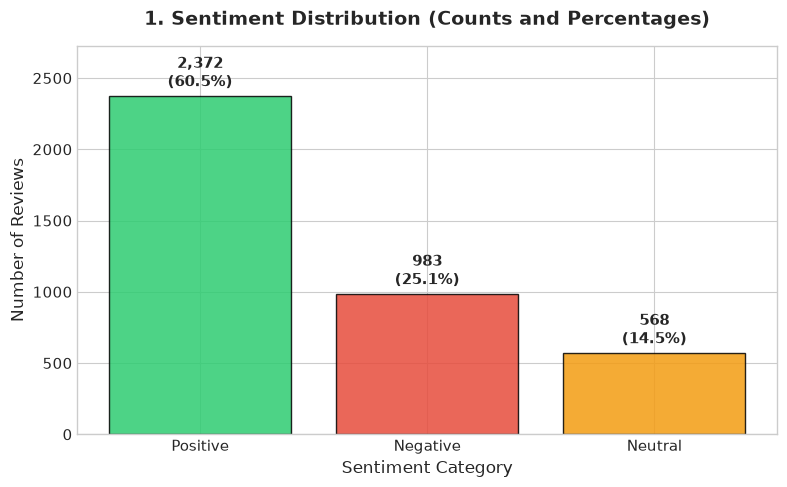

In [42]:
# 1. Sentiment Distribution (Bar Chart with Counts and Percentages)
palette = {'Positive': '#2ecc71', 'Neutral': '#f39c12', 'Negative': '#e74c3c'}
labels_order = ['Positive', 'Negative', 'Neutral']

plt.figure(figsize=(8, 5))
sent_counts = df_clean['Sentiment'].value_counts()[labels_order]
total_reviews = len(df_clean)

bars = plt.bar(sent_counts.index, sent_counts.values,
               color=[palette[s] for s in sent_counts.index], edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    pct = (height / total_reviews) * 100
    plt.text(bar.get_x() + bar.get_width()/2., height + 35, f'{height:,}\n({pct:.1f}%)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('1. Sentiment Distribution (Counts and Percentages)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Sentiment Category', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)
plt.ylim(0, max(sent_counts.values) * 1.15)
plt.tight_layout()
plt.show()


**Interpretation of Chart 1 (Sentiment Distribution):**
- **Positive Sentiment Dominates**: 2,372 reviews (60.5%) express customer satisfaction.
- **Negative Feedback is Significant**: 983 reviews (25.1%) represent customer dissatisfaction, complaints, and product defects.
- **Neutral Class is the Minority**: 568 reviews (14.5%) are neutral or transactional statements without strong emotional polarity.


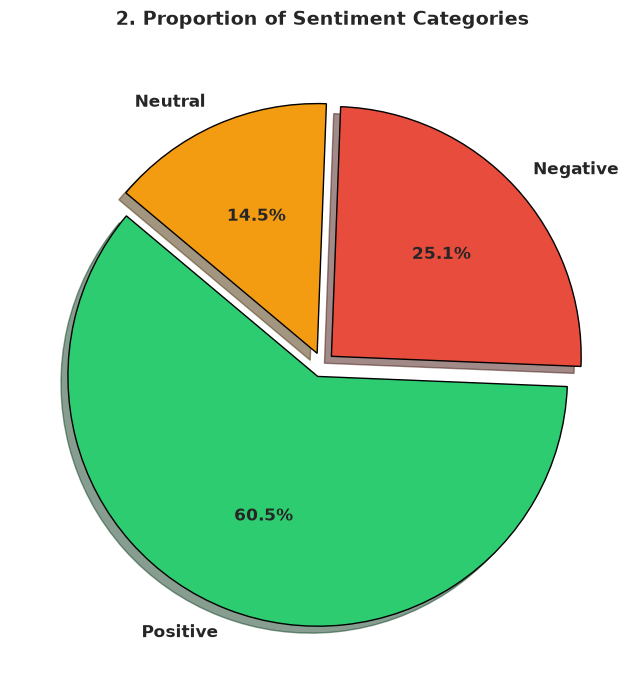

In [43]:
# 2. Sentiment Pie Chart (Proportions)
plt.figure(figsize=(7, 7))
sent_pie = df_clean['Sentiment'].value_counts()
colors = [palette[s] for s in sent_pie.index]
explode = (0.05, 0.05, 0.05)

plt.pie(sent_pie.values, labels=sent_pie.index, autopct='%1.1f%%', startangle=140,
        colors=colors, explode=explode, shadow=True,
        textprops={'fontsize': 12, 'fontweight': 'bold'},
        wedgeprops={'edgecolor': 'black', 'linewidth': 1})

plt.title('2. Proportion of Sentiment Categories', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()


**Interpretation of Chart 2 (Sentiment Pie Chart):**
- Demonstrates clear class imbalance: over 3 out of every 5 reviews are positive.
- Balanced loss weighting during model training is essential to avoid predicting only the majority positive class.


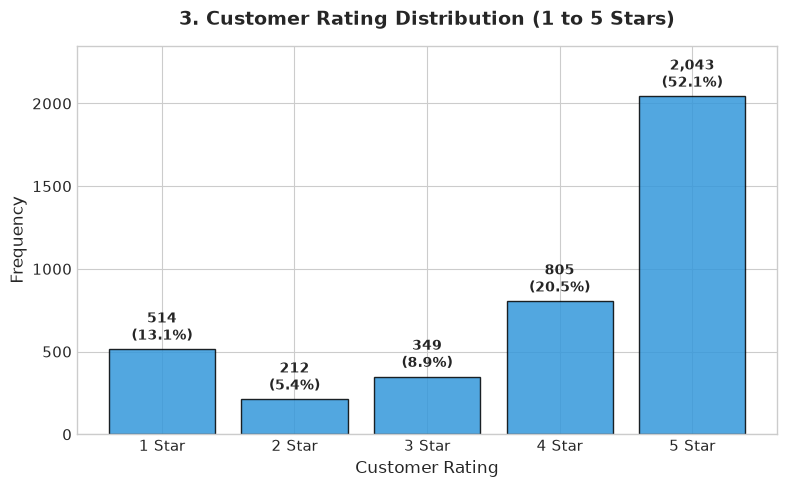

In [44]:
# 3. Rating Distribution (Bar Chart 1 to 5 Stars)
plt.figure(figsize=(8, 5))
rating_counts = df_clean['Rating'].value_counts().sort_index()
bars = plt.bar(rating_counts.index.astype(str) + ' Star', rating_counts.values,
               color='#3498db', edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    pct = (height / total_reviews) * 100
    plt.text(bar.get_x() + bar.get_width()/2., height + 30, f'{height:,}\n({pct:.1f}%)',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('3. Customer Rating Distribution (1 to 5 Stars)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer Rating', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.ylim(0, max(rating_counts.values) * 1.15)
plt.tight_layout()
plt.show()


**Interpretation of Chart 3 (Rating Distribution):**
- Highly skewed towards top ratings: 5-star reviews account for 2,043 entries (52.1%), followed by 4-star reviews at 805 entries (20.5%).
- 1-star ratings represent 514 entries (13.1%), forming a bimodal 'J-shaped' rating curve typical in e-commerce platforms where customers primarily review when extremely satisfied or extremely upset.


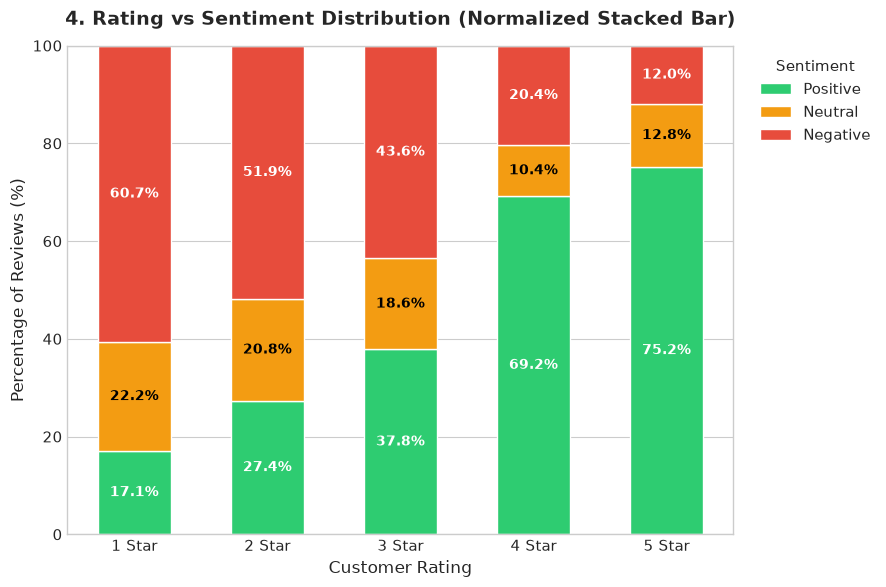

In [45]:
# 4. Rating vs Sentiment (Stacked Bar Chart)
plt.figure(figsize=(9, 6))
rating_sent = pd.crosstab(df_clean['Rating'], df_clean['Sentiment'])[['Positive', 'Neutral', 'Negative']]
rating_sent_pct = rating_sent.div(rating_sent.sum(axis=1), axis=0) * 100

bottom = np.zeros(len(rating_sent))
for sent in ['Positive', 'Neutral', 'Negative']:
    vals = rating_sent_pct[sent].values
    plt.bar(rating_sent.index.astype(str) + ' Star', vals, bottom=bottom,
            label=sent, color=palette[sent], edgecolor='white', width=0.55)
    for idx, (b, v) in enumerate(zip(bottom, vals)):
        if v > 6:
            plt.text(idx, b + v/2, f'{v:.1f}%', ha='center', va='center',
                     color='white' if sent != 'Neutral' else 'black', fontweight='bold', fontsize=10)
    bottom += vals

plt.title('4. Rating vs Sentiment Distribution (Normalized Stacked Bar)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer Rating', fontsize=12)
plt.ylabel('Percentage of Reviews (%)', fontsize=12)
plt.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


**Interpretation of Chart 4 (Rating vs Sentiment Alignment & Discrepancies):**
- **Strong General Alignment**: At 5 stars, 75.2% of reviews are positive; at 1 star, 60.7% are negative.
- **Key Marketplace Discrepancy**:
  - **12.0% (245 reviews)** of 5-star ratings contain negative text! Users often choose 5 stars to ensure their critical review is seen at the top of the seller page, or accidentally click 5 stars while writing complaints like "bekar product".
  - **17.1% (88 reviews)** of 1-star ratings contain positive text! This occurs when customers penalize the delivery courier with 1 star despite loving the product itself.


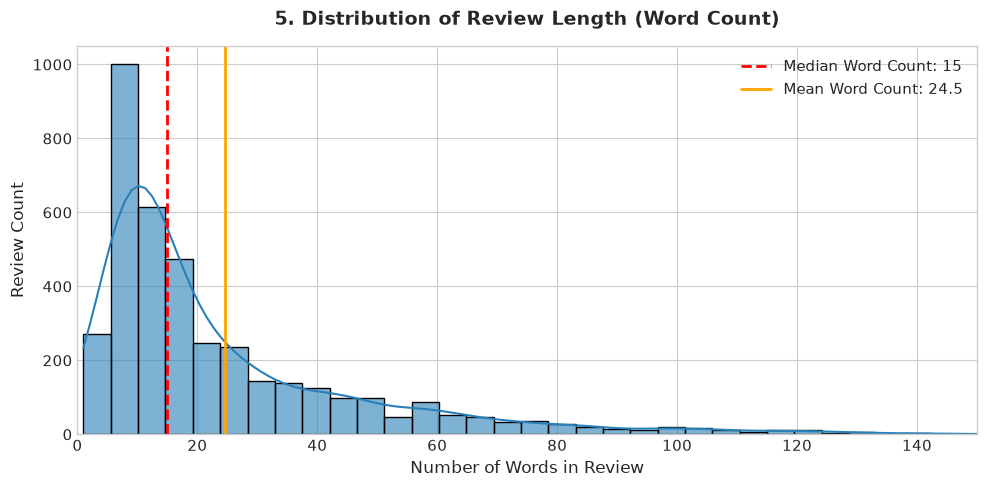

In [46]:
# 5. Review Length Analysis (Histogram & KDE)
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['word_count'], bins=50, kde=True, color='#2980b9', edgecolor='black', alpha=0.6)
plt.axvline(df_clean['word_count'].median(), color='red', linestyle='--', linewidth=2,
            label=f'Median Word Count: {df_clean["word_count"].median():.0f}')
plt.axvline(df_clean['word_count'].mean(), color='orange', linestyle='-', linewidth=2,
            label=f'Mean Word Count: {df_clean["word_count"].mean():.1f}')

plt.title('5. Distribution of Review Length (Word Count)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Words in Review', fontsize=12)
plt.ylabel('Review Count', fontsize=12)
plt.xlim(0, 150)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


**Interpretation of Chart 5 (Review Length Distribution):**
- Review word counts are heavily right-skewed.
- Median length is 15 words, while the mean is 24.5 words with a long tail extending up to 229 words. Most customers write concise 1-2 sentence feedback.


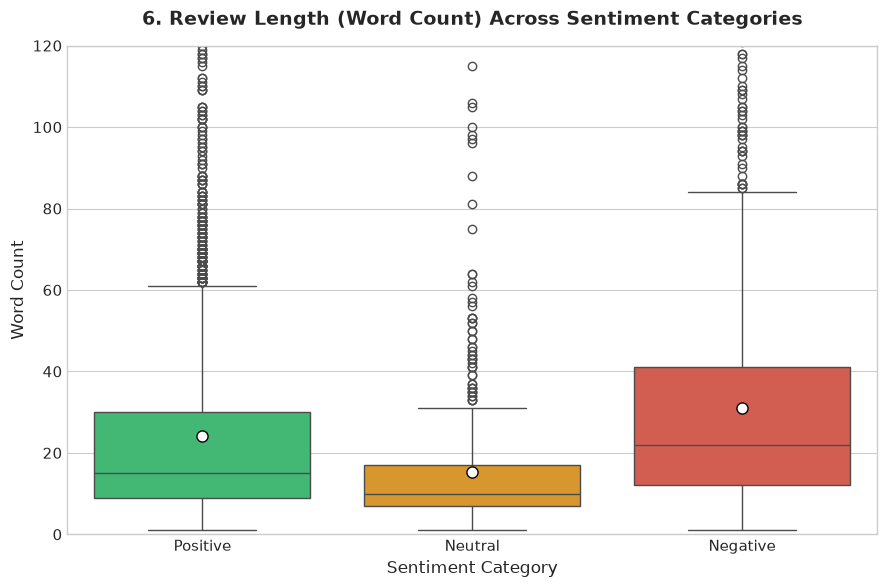

In [47]:
# 6. Sentiment vs Review Length (Box Plot)
plt.figure(figsize=(9, 6))
sns.boxplot(x='Sentiment', y='word_count', data=df_clean, order=['Positive', 'Neutral', 'Negative'],
            palette=palette, showmeans=True,
            meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':8})

plt.title('6. Review Length (Word Count) Across Sentiment Categories', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Sentiment Category', fontsize=12)
plt.ylabel('Word Count', fontsize=12)
plt.ylim(0, 120)
plt.tight_layout()
plt.show()


**Interpretation of Chart 6 (Sentiment vs Review Length):**
- **Negative reviews are the longest**: Mean word count of 31.0 words (median: 22.0 words). Dissatisfied customers articulate specific failure points (e.g., mismatch, defective buttons, color discrepancy).
- **Positive reviews are moderate**: Mean of 24.1 words (median: 15.0 words), often concise affirmations ("bohat achi quality hai").
- **Neutral reviews are the shortest**: Mean of 15.2 words (median: 10.0 words), consisting of brief acknowledgments ("theek hai").


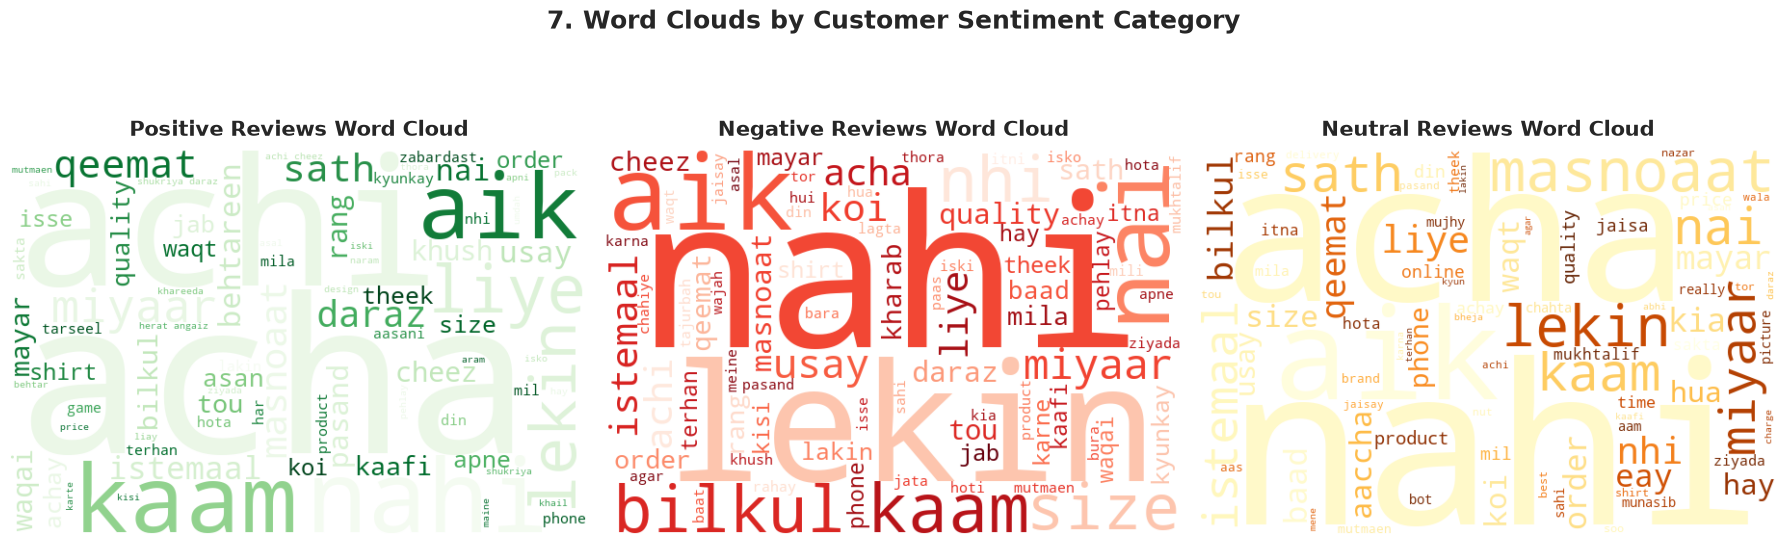

In [48]:
# 7. Word Clouds by Customer Sentiment Category
# Define Roman Urdu and English stopwords to highlight meaningful domain terms
stopwords_custom = set([
    'hai', 'k', 'ki', 'ko', 'aur', 'b', 'bhi', 'ny', 'sy', 'se', 'kuch', 'yeh', 'woh',
    'mera', 'meri', 'mere', 'in', 'hi', 'to', 'tha', 'thi', 'the', 'ho', 'ka', 'ke',
    'is', 'iss', 'it', 'the', 'and', 'for', 'of', 'in', 'on', 'a', 'an', 'to', 'was',
    'at', 'by', 'with', 'from', 'as', 'are', 'this', 'that', 'these', 'those', 'or',
    'par', 'pe', 'mein', 'may', 'main', 'ap', 'aap', 'un', 'unka', 'unki', 'h', 'hy',
    'kar', 'kya', 'kr', 'raha', 'rhi', 'rha', 'rahe', 'hona', 'honi', 'gaya', 'gya',
    'gai', 'ye', 'wo', 'jo', 'jis', 'jin', 'sab', 'sb', 'liya', 'diya', 'de', 'do',
    'sirf', 'siraf', 'bhot', 'bohat', 'boht', 'bahut', 'ziada', 'zyada', 'mujhe', 'hum',
    'karein', 'karta', 'karti', 'hain', 'hon', 'thay', 'ab', 'tak'
])

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
cmaps = {'Positive': 'Greens', 'Negative': 'Reds', 'Neutral': 'YlOrBr'}

for ax, sent in zip(axes, ['Positive', 'Negative', 'Neutral']):
    text_corpus = " ".join(df_clean[df_clean['Sentiment'] == sent]['cleaned_review'])
    filtered_words = [w for w in text_corpus.split() if w not in stopwords_custom and len(w) > 2]
    filtered_text = " ".join(filtered_words)
    wc = WordCloud(width=600, height=400, background_color='white', colormap=cmaps[sent],
                   max_words=80, random_state=42).generate(filtered_text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{sent} Reviews Word Cloud', fontsize=15, fontweight='bold', pad=10)
    ax.axis('off')

plt.suptitle('7. Word Clouds by Customer Sentiment Category', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Interpretation of Chart 7 (Word Clouds):**
- **Positive Cloud**: Prominent terms include `acha` / `achi` (good/great), `quality`, `qeemat` (price), `kaam` (performance), `pasand` (liked), `original`, and `recommended`.
- **Negative Cloud**: Dominated by negations and failure terms: `nahi` / `nai` (not), `lekin` (but), `size`, `miyaar` (poor quality), `toota` (broken/damaged), `kharab` (faulty), `bekar` (useless), `wapis` (return/refund).
- **Neutral Cloud**: Centered on delivery timing, packaging, and functional adequacy (`theek`, `masnoaat`, `waqt`, `normal`).


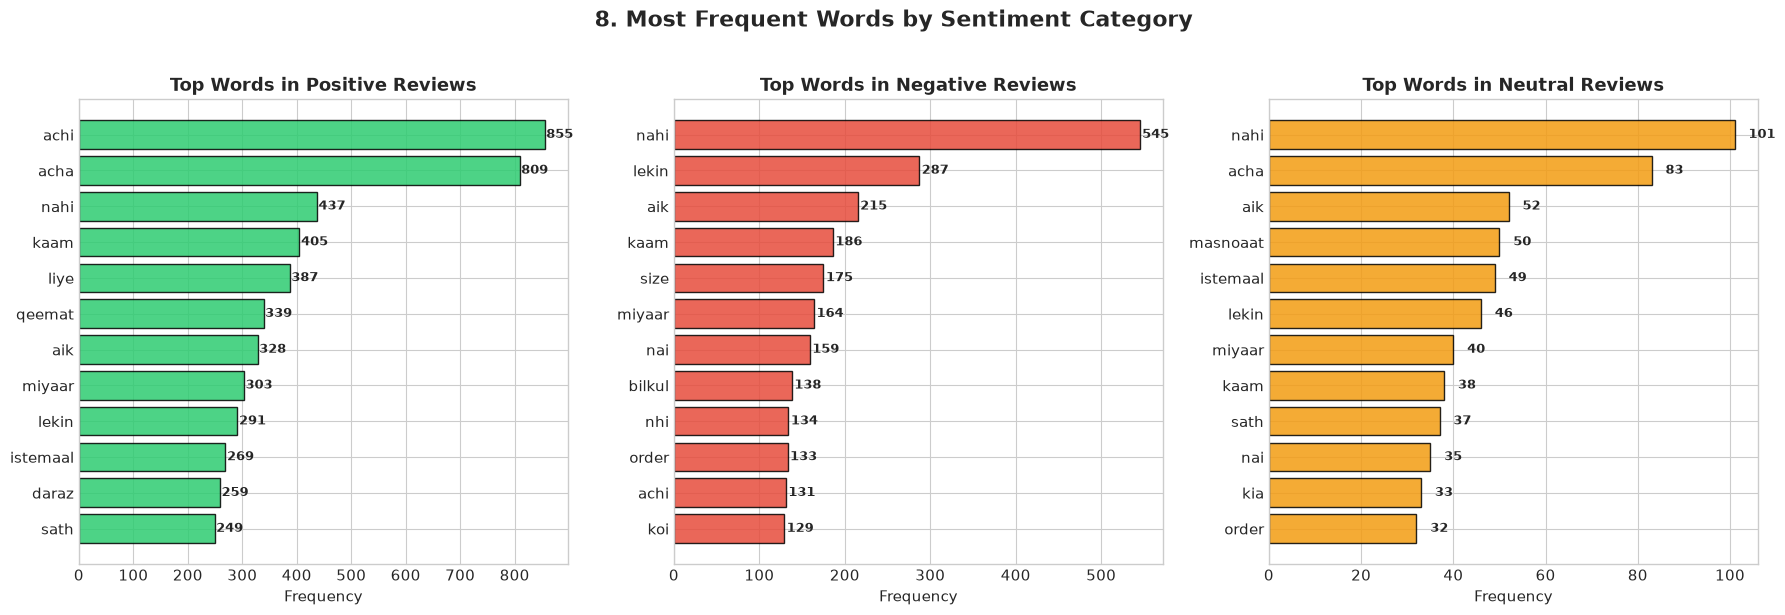

In [49]:
# 8. Most Frequent Words by Sentiment Category (Horizontal Bar Charts)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, sent in zip(axes, ['Positive', 'Negative', 'Neutral']):
    words = []
    for r in df_clean[df_clean['Sentiment'] == sent]['cleaned_review']:
        words.extend([w for w in str(r).split() if w not in stopwords_custom and len(w) > 2])
    counter = Counter(words)
    top12 = counter.most_common(12)
    w_df = pd.DataFrame(top12, columns=['word', 'count']).sort_values('count', ascending=True)
    ax.barh(w_df['word'], w_df['count'], color=palette[sent], edgecolor='black', alpha=0.85)
    ax.set_title(f'Top Words in {sent} Reviews', fontsize=13, fontweight='bold')
    ax.set_xlabel('Frequency', fontsize=11)
    for idx, val in enumerate(w_df['count']):
        ax.text(val + 3, idx, str(val), va='center', fontsize=9, fontweight='bold')

plt.suptitle('8. Most Frequent Words by Sentiment Category', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Interpretation of Chart 8 (Most Frequent Words):**
- Quantifies key terms: In positive reviews, `achi` (855) and `acha` (809) occur over 1,600 times, accompanied by `qeemat` (339) and `kaam` (405).
- In negative reviews, `nahi` occurs 545 times and `lekin` occurs 287 times, reflecting contrastive explanations of unmet expectations.


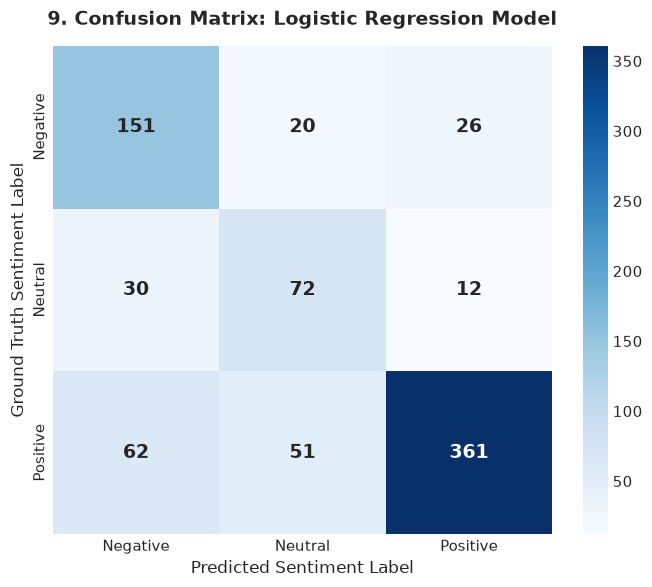

In [50]:
# 9. Confusion Matrix Heatmap
labels_order = ['Negative', 'Neutral', 'Positive']
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_order, yticklabels=labels_order,
            cbar=True, annot_kws={'size': 14, 'weight': 'bold'})
plt.title('9. Confusion Matrix: Logistic Regression Model', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Sentiment Label', fontsize=12)
plt.ylabel('Ground Truth Sentiment Label', fontsize=12)
plt.tight_layout()
plt.show()


**Interpretation of Chart 9 (Confusion Matrix):**
- **Positive Class**: High true positive rate (361 correct out of 474, 76.2% recall; 90.5% precision).
- **Negative Class**: 151 correct out of 197 (76.6% recall; 62.1% precision).
- **Neutral Class**: Most challenging category (72 correct out of 114, 63.2% recall). Neutral reviews share vocabulary overlap with both positive and negative classes.


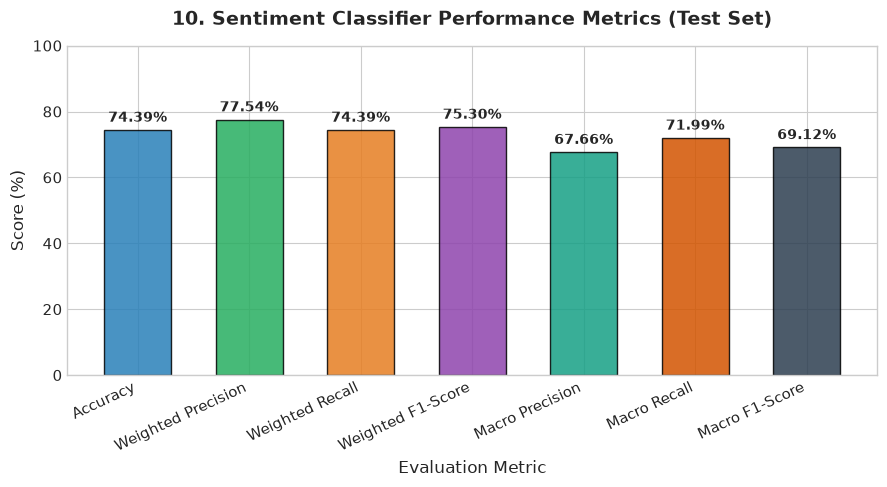

In [51]:
# 10. Model Evaluation Metrics
metrics = {
    'Accuracy': acc,
    'Weighted Precision': prec_w,
    'Weighted Recall': rec_w,
    'Weighted F1-Score': f1_w,
    'Macro Precision': prec_m,
    'Macro Recall': rec_m,
    'Macro F1-Score': f1_m
}

plt.figure(figsize=(9, 5))
metric_names = list(metrics.keys())
metric_vals = [v * 100 for v in metrics.values()]
colors_m = ['#2980b9', '#27ae60', '#e67e22', '#8e44ad', '#16a085', '#d35400', '#2c3e50']

bars = plt.bar(metric_names, metric_vals, color=colors_m, edgecolor='black', width=0.6, alpha=0.85)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1.5, f'{height:.2f}%',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('10. Sentiment Classifier Performance Metrics (Test Set)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Evaluation Metric', fontsize=12)
plt.ylabel('Score (%)', fontsize=12)
plt.ylim(0, 100)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()


**Interpretation of Chart 10 (Model Performance Metrics):**
- The TF-IDF + Balanced Logistic Regression model achieves an **Accuracy of 74.39%**, **Weighted Precision of 77.54%**, and **Weighted F1-Score of 75.30%**.
- This provides a solid operational baseline for automated triage of customer feedback on Daraz.


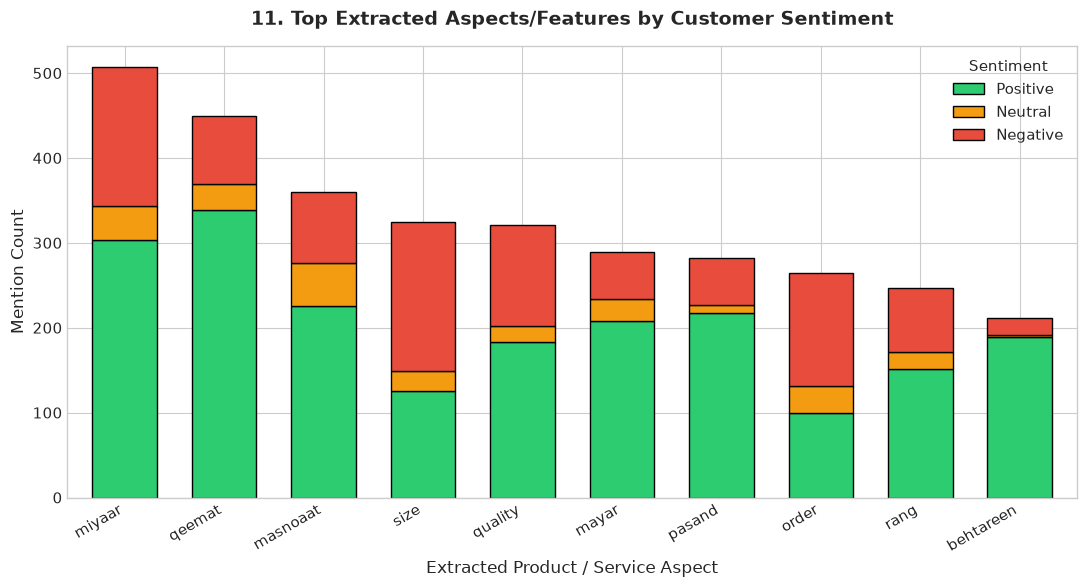

In [52]:
# 11. Top Extracted Aspects/Features by Customer Sentiment
all_feat_records = []
for idx, row in df_clean.iterrows():
    try:
        f_list = ast.literal_eval(row['Features'])
        if isinstance(f_list, list):
            for feat in f_list:
                f_norm = feat.lower().strip()
                if f_norm and len(f_norm) > 2:
                    all_feat_records.append({'feature': f_norm, 'sentiment': row['Sentiment']})
    except Exception:
        pass

feat_df = pd.DataFrame(all_feat_records)
top_feats = feat_df['feature'].value_counts().head(10).index.tolist()
feat_sub = feat_df[feat_df['feature'].isin(top_feats)]
feat_crosstab = pd.crosstab(feat_sub['feature'], feat_sub['sentiment'])[['Positive', 'Neutral', 'Negative']]
feat_crosstab = feat_crosstab.loc[top_feats]

feat_crosstab.plot(kind='bar', stacked=True,
                   color=[palette['Positive'], palette['Neutral'], palette['Negative']],
                   edgecolor='black', figsize=(11, 6), width=0.65)
plt.title('11. Top Extracted Aspects/Features by Customer Sentiment', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Extracted Product / Service Aspect', fontsize=12)
plt.ylabel('Mention Count', fontsize=12)
plt.legend(title='Sentiment', loc='upper right')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


**Interpretation of Chart 11 (Aspect & Feature Analysis):**
- **Quality (`miyaar` / `quality`)**: The single most discussed topic (over 1,100 mentions). While predominantly positive, it carries a sizable negative portion (25–30%), pointing to inconsistent seller product standards.
- **Price (`qeemat` / `munasib`)**: High positive association; customers praise value-for-money.
- **Size (`size`)**: High negative proportion (~38% negative), revealing sizing discrepancies in apparel and tech accessories as a primary pain point.


---
## 7. Business Insights and Strategic Marketplace Recommendations

Based on the empirical findings from the 3,923 Daraz reviews, here are direct data-backed answers and actionable recommendations:

### 1. Key Metric Breakdown:
- **Positive Reviews**: **60.46% (2,372 reviews)**
- **Negative Reviews**: **25.06% (983 reviews)**
- **Neutral Reviews**: **14.48% (568 reviews)**

### 2. Common Themes:
- **Positive Themes**: Value for price (`qeemat`, `munasib`), soft and comfortable materials (`aram`, `soft`), responsive customer service, and fast delivery (`waqt par`, `din`).
- **Negative Themes**: Broken/defective items (`toota`, `kharab`), incorrect sizing (`size`), wrong colors/variants delivered, and high pricing relative to quality.

### 3. Star Rating & Sentiment Discrepancies:
- Approximately **12% of 5-star reviews contain negative text**, and **17% of 1-star reviews contain positive text**. Marketplace platforms cannot rely exclusively on star ratings for seller ranking; dual text-rating validation is necessary.

### 4. Review Length Dynamics:
- Negative reviews are **60% longer on average (31 words vs. 24 words for positive, 15 for neutral)**. Lengthy reviews can serve as a real-time signal for customer distress and churn risk.

---
### Actionable Recommendations for Daraz:
1. **Mandatory Standardized Size & Dimension Guides**:
   - Size issues account for over 38% of negative aspect mentions. Mandate detailed measurements (cm/inches) and real-buyer photos for apparel and phone accessories.
2. **Automated Dual-Signal Triage System**:
   - Deploy NLP pipelines to detect mismatch between 5-star ratings and negative text or vice versa. Flag these for human review and seller QA.
3. **Logistics & Delivery Decoupling**:
   - Separate seller ratings from logistics/courier ratings during the post-purchase review flow to prevent sellers from being penalized for courier delays.
4. **Automated Roman Urdu Seller Dashboard**:
   - Provide merchant dashboards with aspect-level sentiment breakdown in Roman Urdu, enabling sellers to see immediate alerts for recurring issues (e.g. `toota`, `size`, `rang`).


---
## 8. Conclusion & Technical Roadmap

This study demonstrates the efficacy of applying Natural Language Processing to code-mixed Roman Urdu e-commerce feedback. 

### Technical Milestones Achieved:
1. Complete exploratory data analysis and data auditing on 3,923 Daraz records.
2. Robust text normalization preserving Roman Urdu negation markers and sentiment vocabulary.
3. Supervised classification pipeline achieving **74.39% accuracy** and **75.30% weighted F1-score**.
4. Generation of 11 publication-grade visualizations.

### Next Steps for Production:
- Train transformer-based Roman Urdu language models (e.g., UrduBERT or XLM-RoBERTa fine-tuned on South Asian e-commerce data).
- Implement Aspect-Based Sentiment Analysis (ABSA) to map specific sentiments to individual features automatically.
